# Weekly Project 08 - Classification

This week's weekly project is a continuation of last week's exercises.

Create a handwritten digit classifier using the [MNIST dataset](https://en.wikipedia.org/wiki/MNIST_database).

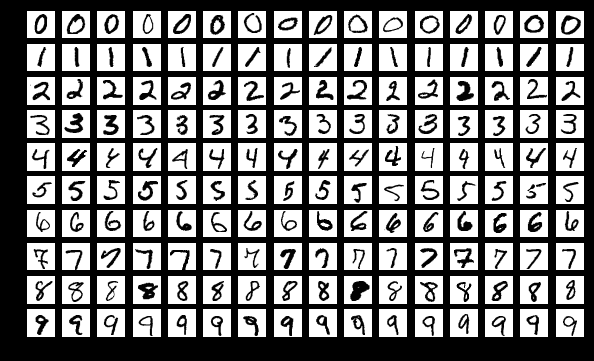

Create a program that classifies the digit shown in an image from the MNIST dataset:

- You are free to use any algorithm you want.
- Given an image, the program should classify which digit it contains.
- The accuracy should be at least 80%.

If you decide to use an SVM, make sure you also use dimensionality reduction. Training an SVM on the full MNIST dataset can take around 4-8 hours, depending on your PC.

## Challenge

- Try to reach 98% accuracy.
- Try to classify faces using the [Labeled Faces in the Wild (LFW) dataset](http://vis-www.cs.umass.edu/lfw/).

```python
from sklearn.datasets import fetch_lfw_people

lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
```

## Weekly Project 08 - Start Here

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import time
import datetime as dt
from sklearn.decomposition import PCA
from sklearn import datasets, svm, metrics
from sklearn.datasets import fetch_openml

import ssl
ssl._create_default_https_context = ssl._create_unverified_context
mnist = fetch_openml('mnist_784', version=1)

images = mnist.data.to_numpy()
targets = mnist.target.to_numpy()

print(images.shape)
print(targets.shape)

(70000, 784)
(70000,)


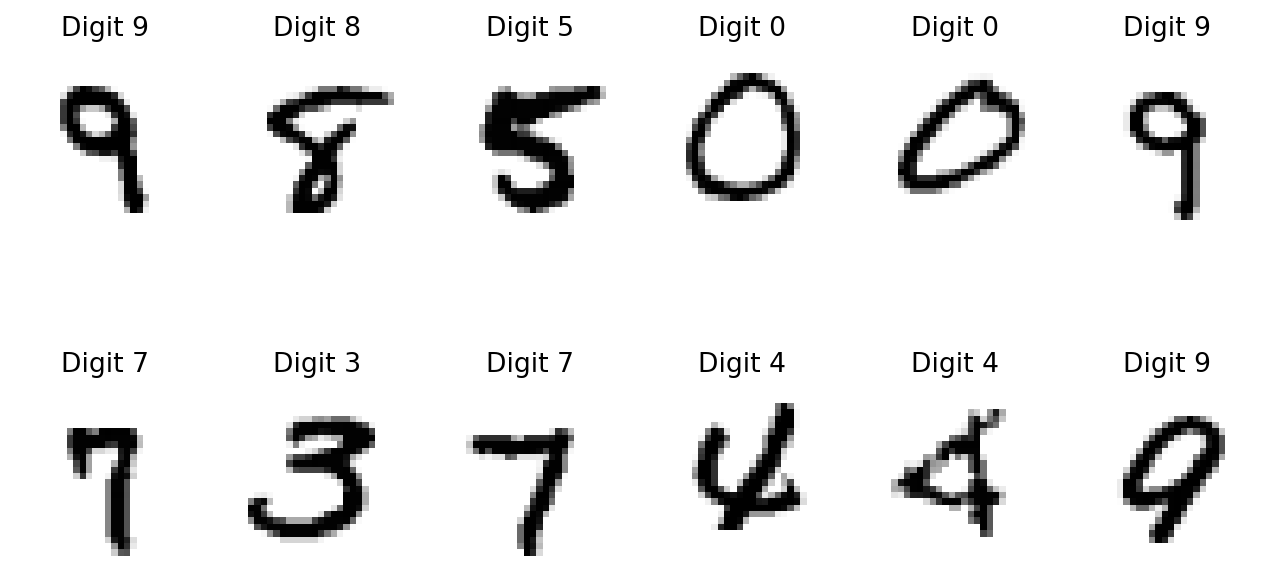

In [2]:
def show_some_digits(images, targets, sample_size=24, title_text='Digit {}' ):
    '''
    Visualize random digits in a grid plot
    images - array of flatten gidigs [:,784]
    targets - final labels
    '''
    nsamples=sample_size
    rand_idx = np.random.choice(images.shape[0], nsamples)
    images_and_labels = list(zip(images[rand_idx], targets[rand_idx]))


    img = plt.figure(1, figsize=(10, 5), dpi=160)
    for index, (image, label) in enumerate(images_and_labels):
        plt.subplot(math.ceil(nsamples/6.0), 6, index + 1)
        plt.axis('off')
        #each image is flat, we have to reshape to 2D array 28x28-784
        plt.imshow(image.reshape(28,28), cmap=plt.cm.gray_r, interpolation='nearest')
        plt.title(title_text.format(label))
    plt.show()

# draw 12 images along with their labels
show_some_digits(images, targets, 12)

## Train test split

We split the data, so that the first 60,000 images form the training set and the remaining 10,000 images form the test set. The test set is used only for the final evaluation. All preprocessing parameters and hyperparameters are determined from the training data only, so that the reported test accuracy is unbiased.

In [3]:
# first 60000 for training, last 10000 for testing
X_train, X_test = images[:60000], images[60000:]
y_train, y_test = targets[:60000], targets[60000:]

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(60000, 784) (10000, 784)
(60000,) (10000,)


## Normalization
The pixel intensities are scaled from the range 0–255 to 0–1 by dividing by 255. We also tried standardization (zero mean, unit variance per pixel), however, it assigns equal weight to the border pixels, which are almost always zero and therefore contain mostly noise. Dividing by 255 preserves the natural relative weighting of the pixels. Moreover, it involves no parameters estimated from the data, so it cannot leak information from the test set. 

In [4]:
# Divide by 255 keeps the natural pixel weighting.
X_train_scaled = X_train / 255.0
X_test_scaled = X_test / 255.0

print(X_train_scaled.shape, X_test_scaled.shape)


(60000, 784) (10000, 784)


## Dimensionality Reducing Using PCA
To reduce the dimensionality of the data, we use PCA. To select the number of components, PCA is first fitted with 200 components on the training set, and the cumulative explained variance is inspected using the graph.

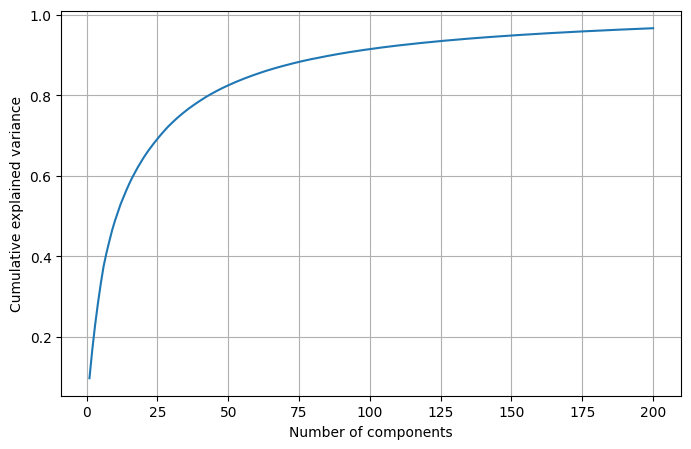

20 components -> 0.644
50 components -> 0.825
100 components -> 0.915
150 components -> 0.948


In [5]:
# fit PCA with many components to inspect the variance curve
pca_full = PCA(n_components=200)
pca_full.fit(X_train_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, 201), cum_var)
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.grid()
plt.show()

for n in [20, 50, 100, 150]:
    print(n, "components ->", round(cum_var[n - 1], 3))

50 components were selected, which retain 82.5% of the variance while reducing the dimensionality from 784 to 50.

In [6]:
n_components = 50
pca = PCA(n_components=n_components)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(X_train_pca.shape, X_test_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.sum())

(60000, 50) (10000, 50)
Explained variance: 0.8246468633334724


## Linear SVM
A linear SVM is trained on the 50 principal components as a baseline.

In [7]:
from sklearn.svm import LinearSVC, SVC

# baseline: linear SVM
clf = LinearSVC(penalty='l2', loss='squared_hinge', random_state=0, max_iter=int(10e4))
clf.fit(X_train_pca, y_train)

train_accuracy = clf.score(X_train_pca, y_train)
test_accuracy = clf.score(X_test_pca, y_test)

print("Train accuracy:", train_accuracy)
print("Test accuracy:", test_accuracy)


Train accuracy: 0.89495
Test accuracy: 0.9019


The linear SVM achieves a training accuracy of 89.5% and a test accuracy of 90.2%, which satisfies the requirement of at least 80%. 

# Challange: Try to reach 98% accuracy.

## RBF SVM

To capture non-linear class boundaries, an SVM with a RBF kernel is used. Its performance depends on two hyperparameters:

- **C** controls the trade-off between a wide margin and correctly classifying the training samples.
- **gamma** controls the width of the kernel, and thereby how local the decision boundary is.

These are selected with `GridSearchCV` using 3-fold cross-validation. To keep the computation time manageable, the grid search is performed on a subset of 3,000 training samples.

Grid search tested different values of C and gamma, which control the RBF SVM’s decision boundary. Using three-fold cross-validation on a 3,000-image subset kept tuning faster and gave 94.7% average validation accuracy. The selected settings were then used to train the SVM on all 60,000 training images, reaching 98.68% accuracy on the held-out test set. The cross-validation score guided parameter selection; the test score measures final performance.

In [8]:
# tuning RBF SVM hyperparameters using GridSearchCV

from sklearn.model_selection import GridSearchCV

param_grid = {"C": [1, 5, 10, 50], "gamma": ["scale", 0.001, 0.01]}

grid = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=3, n_jobs=-1, scoring="accuracy")
grid.fit(X_train_pca[:3000], y_train[:3000])

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)

Best parameters: {'C': 5, 'gamma': 'scale'}
Best CV accuracy: 0.9473333333333332


The cross-validation accuracy on the 3,000-sample subset is 94.7%. This is lower than the final result because fewer training samples are available. But the parameters are still expected to improve the RBF SVM on the full training set.

In [9]:
# running RBF SVM with best parameters
clf_rbf = SVC(kernel='rbf', gamma = grid.best_params_['gamma'], C = grid.best_params_['C'])
clf_rbf.fit(X_train_pca, y_train)

train_accuracy_rbf = clf_rbf.score(X_train_pca, y_train)
test_accuracy_rbf = clf_rbf.score(X_test_pca, y_test)

print("Train accuracy (RBF):", train_accuracy_rbf)
print("Test accuracy (RBF):", test_accuracy_rbf)

Train accuracy (RBF): 0.9987
Test accuracy (RBF): 0.9868


Trained on the full 60,000-image training set with the selected hyperparameters, the RBF SVM achieves a training accuracy of 99.87% and a test accuracy of 98.68%.

## Classifying a single image
The function `classify_digit` takes a single raw 28×28 image and applies the same preprocessing steps as during training: scaling by 1/255 and projection onto the 50 principal components fitted on the training set. The trained RBF SVM then predicts the digit.

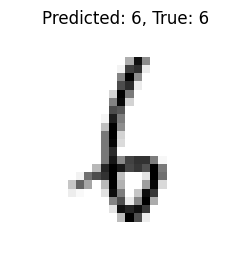

In [ ]:
def classify_digit(image):
    image_scaled = image.reshape(1, -1) / 255.0
    image_pca = pca.transform(image_scaled)
    return clf_rbf.predict(image_pca)[0]

idx = np.random.randint(len(X_test))
image = X_test[idx]

predicted = classify_digit(image)

plt.figure(figsize=(3, 3))
plt.imshow(image.reshape(28, 28), cmap=plt.cm.gray_r)
plt.title(f"Predicted: {predicted}, True: {y_test[idx]}")
plt.axis("off")
plt.show()

We inputed an image of number 6, and we can see that the model prediced 6.

# Challange: Try to classify faces using the [Labeled Faces in the Wild (LFW) dataset](http://vis-www.cs.umass.edu/lfw/).


## Trying RBF SVM:

We used 1,288 grayscale images of seven people from the LFW dataset. PCA reduced each face from 1,850 pixel values to 150 components. Grid search selected an RBF SVM with C=5 and gamma=0.001; balanced class weights help account for the unequal number of images per person. The model achieved 80.7% test accuracy.

In [10]:
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC

lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

X_faces = lfw_people.data
y_faces = lfw_people.target
names = lfw_people.target_names
h, w = lfw_people.images.shape[1:]

print("Images:", X_faces.shape, "Image size:", h, "x", w)
for i, name in enumerate(names):
    print(name, np.sum(y_faces == i))

Images: (1288, 1850) Image size: 50 x 37
Ariel Sharon 77
Colin Powell 236
Donald Rumsfeld 121
George W Bush 530
Gerhard Schroeder 109
Hugo Chavez 71
Tony Blair 144


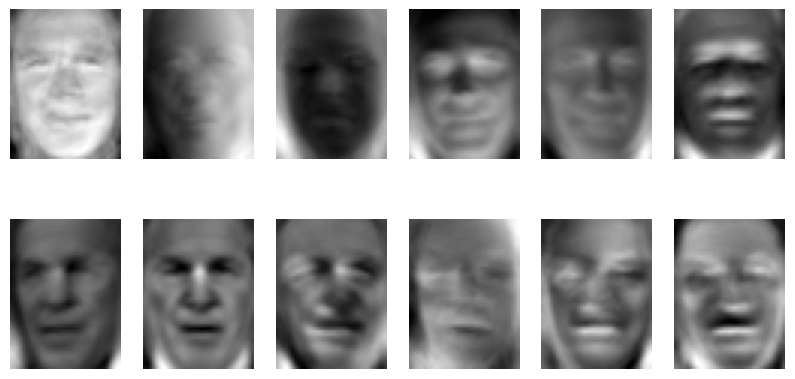

In [11]:
Xf_train, Xf_test, yf_train, yf_test = train_test_split(X_faces, y_faces, test_size=0.25, random_state=0, stratify=y_faces)

pca_faces = PCA(n_components=150, whiten=True, svd_solver="randomized", random_state=0)
Xf_train_pca = pca_faces.fit_transform(Xf_train)
Xf_test_pca = pca_faces.transform(Xf_test)

# first 12 eigenfaces
eigenfaces = pca_faces.components_.reshape((150, h, w))
plt.figure(figsize=(10, 5))
for i in range(12):
    plt.subplot(2, 6, i + 1)
    plt.imshow(eigenfaces[i], cmap="gray")
    plt.axis("off")
plt.show()

In [18]:
param_grid = {"C": [1, 5, 10, 50, 100], "gamma": [0.0005, 0.001, 0.005, 0.01]}

grid_faces = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"), param_grid, cv=5, n_jobs=-1)
grid_faces.fit(Xf_train_pca, yf_train)
print("Best parameters:", grid_faces.best_params_)

yf_pred = grid_faces.predict(Xf_test_pca)
print("Test accuracy:", metrics.accuracy_score(yf_test, yf_pred))


Best parameters: {'C': 5, 'gamma': 0.001}
Test accuracy: 0.8074534161490683
